# Sélection de variables (version allégée) — King County House Prices

**Objectif :** choisir les variables à garder pour prédire le prix, sans valider avec un modèle final.

| Méthode | Rôle | Vote ? |
|---|---|---|
| Information mutuelle | filtre non linéaire | oui |
| Lasso (règle 1-SE) | vue linéaire | oui |
| Forward selection | vue linéaire, variables ajoutées une à une | oui |
| Boruta | vue non linéaire (Random Forest) | oui |
| VIF | contrôle de redondance | non |

Une variable `random_noise` (bruit pur) sert de témoin : aucune méthode ne devrait la retenir.
Les découpages de validation croisée sont groupés par `id` (des maisons vendues deux fois).

## 0. Vérification des paquets
Cette cellule n'installe rien : elle vérifie les paquets et, s'il en manque, affiche la commande exacte à lancer dans un terminal (puis redémarrer le noyau).

In [12]:
import importlib.util, sys
requis = {"mlxtend": "mlxtend", "boruta": "boruta", "statsmodels": "statsmodels", "seaborn": "seaborn", "scikit-learn": "sklearn"}
manquants = [pkg for pkg, mod in requis.items() if importlib.util.find_spec(mod) is None]
if manquants:
    print("Paquets manquants :", manquants)
    print("Lance cette commande dans un terminal, puis redémarre le noyau :\n")
    print(f'  "{sys.executable}" -m pip install ' + " ".join(manquants))
else:
    print("Tous les paquets nécessaires sont installés.")

Tous les paquets nécessaires sont installés.


In [ ]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from matplotlib.colors import ListedColormap

# BorutaPy utilise encore np.int / np.float / np.bool (supprimés des versions récentes de NumPy)
for _a, _t in [("int", int), ("float", float), ("bool", bool)]:
    if not hasattr(np, _a): setattr(np, _a, _t)

from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from statsmodels.stats.outliers_influence import variance_inflation_factor
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from boruta import BorutaPy

sns.set_theme(style="whitegrid"); RS = 42
DATA_PATH = "kc_house_data.csv"   

from pathlib import Path
if not Path(DATA_PATH).exists():
    raise FileNotFoundError(f"Fichier introuvable : {Path(DATA_PATH).resolve()}\n"
                            "Place kc_house_data.csv à côté du notebook ou modifie DATA_PATH.")

## 1. Chargement et préparation

In [14]:
df = pd.read_csv(DATA_PATH, skipinitialspace=True, quotechar='"')
df.columns = df.columns.str.strip()
for c in ["id", "date", "floors", "zipcode"]:
    df[c] = df[c].astype(str).str.strip().str.strip('"')
df["floors"] = df["floors"].astype(float)
df["date"] = pd.to_datetime(df["date"].str[:8], format="%Y%m%d")

df = df[df["bedrooms"] < 30].copy()                      # ligne aberrante (33 chambres)
df["sale_year"]    = df["date"].dt.year
df["sale_month"]   = df["date"].dt.month
df["house_age"]    = (df["sale_year"] - df["yr_built"]).clip(lower=0)
df["is_renovated"] = (df["yr_renovated"] > 0).astype(int)
df["has_basement"] = (df["sqft_basement"] > 0).astype(int)
df["random_noise"] = np.random.RandomState(RS).normal(size=len(df))   # variable témoin

groups = df["id"].values
y = np.log(df["price"])                                   # cible : log(prix)
X = df.drop(columns=["id", "date", "zipcode", "price"])
print(f"{len(df)} lignes, {X.shape[1]} variables candidates :", list(X.columns))

21612 lignes, 23 variables candidates : ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 'house_age', 'is_renovated', 'has_basement', 'random_noise']


## 2. Préparation commune (standardisation + plis de validation groupés)

In [ ]:
Xs = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns, index=X.index)
cv = list(GroupKFold(n_splits=5).split(X, y, groups))     # mêmes plis
votes = pd.DataFrame(index=X.columns)                     # True = variable retenue

## 3. Information mutuelle (filtre)
Seuil : au moins 5 fois l'information mutuelle de la variable de bruit.

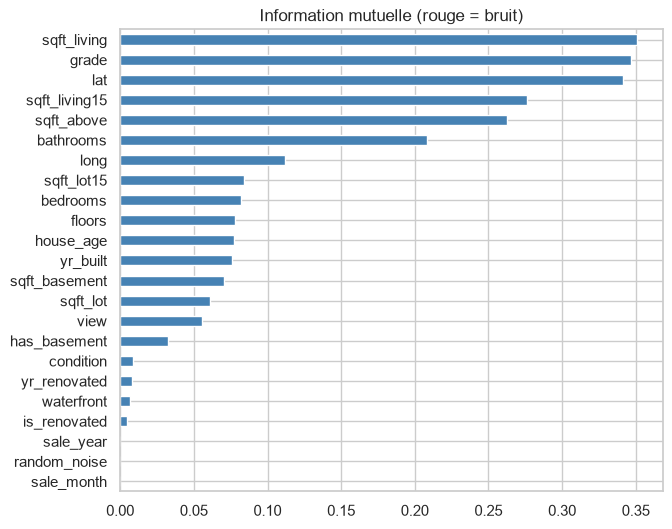

Retenues : 19


In [16]:
mi = pd.Series(mutual_info_regression(X, y, random_state=RS), index=X.columns).sort_values()
votes["Info mutuelle"] = mi.reindex(X.columns) >= 5 * max(mi["random_noise"], 1e-3)

mi.plot.barh(figsize=(7, 6), color=["crimson" if i == "random_noise" else "steelblue" for i in mi.index],
             title="Information mutuelle (rouge = bruit)"); plt.show()
print("Retenues :", int(votes["Info mutuelle"].sum()))

In [ ]:
######################
######################
######################
######################
######################
######################
######################
######################
######################

## 4. Lasso avec règle 1-SE
On prend la pénalité la plus forte dont l'erreur reste à moins d'une erreur-type du minimum : un modèle plus simple pour une performance proche.

alpha_min = 0.00037 | alpha_1se = 0.00616


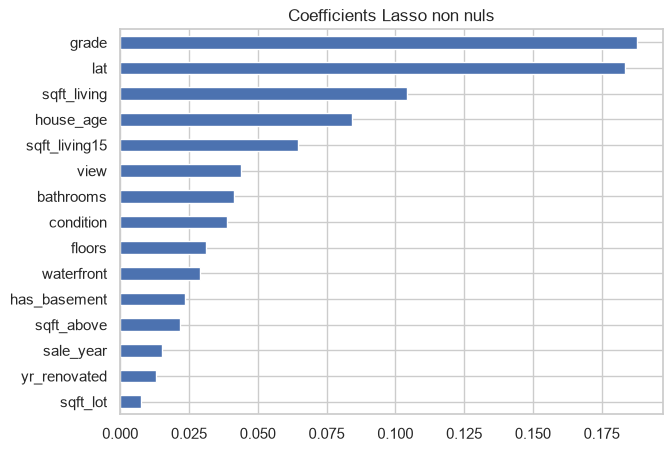

In [17]:
# grille d'alphas explicite (compatible avec toutes les versions de scikit-learn)
alpha_max = np.max(np.abs(Xs.values.T @ (y.values - y.mean()))) / len(Xs)
alphas = np.logspace(np.log10(alpha_max), np.log10(alpha_max * 1e-3), 60)
lasso = LassoCV(alphas=alphas, cv=cv, random_state=RS, max_iter=20000).fit(Xs, y)
mse_mean = lasso.mse_path_.mean(axis=1)
mse_se   = lasso.mse_path_.std(axis=1) / np.sqrt(lasso.mse_path_.shape[1])
i_min    = mse_mean.argmin()
alpha_1se = lasso.alphas_[np.where(mse_mean <= mse_mean[i_min] + mse_se[i_min])[0][0]]

lasso1 = LassoCV(alphas=[alpha_1se], cv=cv, max_iter=20000).fit(Xs, y)
coef = pd.Series(lasso1.coef_, index=X.columns)
votes["Lasso (1-SE)"] = coef.abs() > 1e-6

print(f"alpha_min = {lasso.alpha_:.5f} | alpha_1se = {alpha_1se:.5f}")
coef[coef != 0].sort_values().plot.barh(figsize=(7, 5), title="Coefficients Lasso non nuls"); plt.show()

## 5. Forward selection
On part de zéro variable et on ajoute à chaque tour celle qui améliore le plus le R² (régression linéaire, validation croisée groupée). Sous-échantillon de 5 000 lignes pour la vitesse.

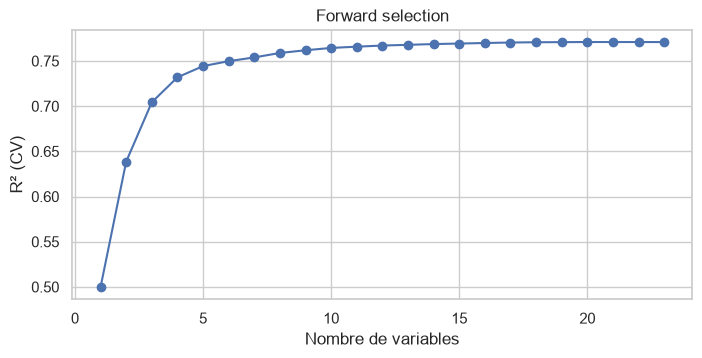

Forward : 21 variables retenues


In [18]:
ws = np.random.RandomState(RS).choice(len(X), 5000, replace=False)
Xw, yw = Xs.iloc[ws], y.iloc[ws]
cv_w = list(GroupKFold(n_splits=3).split(Xw, yw, groups[ws]))

sfs = SFS(LinearRegression(), k_features="best", forward=True, floating=False,
          scoring="r2", cv=cv_w, n_jobs=1).fit(Xw, yw)
fwd_sel = list(sfs.k_feature_names_)
votes["Forward SFS"] = votes.index.isin(fwd_sel)

path = pd.DataFrame(sfs.get_metric_dict()).T
plt.figure(figsize=(8, 3.5)); plt.plot(path.index.astype(int), path["avg_score"].astype(float), "o-")
plt.xlabel("Nombre de variables"); plt.ylabel("R² (CV)"); plt.title("Forward selection"); plt.show()
print(f"Forward : {len(fwd_sel)} variables retenues")

## 6. Boruta
Boruta crée des copies mélangées de chaque variable et ne garde que celles qui battent la meilleure copie. Sous-échantillon de 4 000 lignes.

In [19]:
sub = np.random.RandomState(RS).choice(len(X), 4000, replace=False)
rf_b = RandomForestRegressor(n_jobs=-1, max_depth=6, min_samples_leaf=10, random_state=RS)
boruta = BorutaPy(rf_b, n_estimators="auto", max_iter=25, perc=100, alpha=0.05, random_state=RS, verbose=0)
boruta.fit(X.iloc[sub].values, y.iloc[sub].values)
votes["Boruta"] = boruta.support_

status = pd.Series(np.where(boruta.support_, "Confirmed", np.where(boruta.support_weak_, "Tentative", "Rejected")), index=X.columns)
for s in ["Confirmed", "Tentative", "Rejected"]:
    print(f"{s:10s}:", list(status[status == s].index))

Confirmed : ['sqft_living', 'sqft_lot', 'view', 'grade', 'sqft_above', 'yr_built', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'house_age']
Tentative : ['bathrooms']
Rejected  : ['bedrooms', 'floors', 'waterfront', 'condition', 'sqft_basement', 'yr_renovated', 'sale_year', 'sale_month', 'is_renovated', 'has_basement', 'random_noise']


## 7. VIF : contrôle de redondance (ne vote pas)
Le VIF repère les variables dont l'information est déjà contenue dans les autres (ex. `sqft_living = sqft_above + sqft_basement`). Seuil usuel : 10.

In [20]:
def vif_table(cols):
    Z = Xs[cols].assign(const=1.0)
    with warnings.catch_warnings():                       # dépendances exactes -> VIF infini, avertissement attendu
        warnings.simplefilter("ignore")
        return pd.Series([variance_inflation_factor(Z.values, i) for i in range(len(cols))], index=cols)

votes["VIF≤10"] = False
cols = [c for c in X.columns if c != "random_noise"]
while True:
    v = vif_table(cols)
    if v.max() <= 10: break
    cols.remove(v.idxmax())
votes["VIF≤10"] = votes.index.isin(cols)
print("Variables non redondantes (VIF≤10) :", cols)

Variables non redondantes (VIF≤10) : ['bedrooms', 'bathrooms', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 'is_renovated', 'has_basement']


## 8. Consensus
Une variable est retenue si elle a au moins `THRESH` votes parmi les 4 méthodes de pertinence (le VIF ne vote pas).

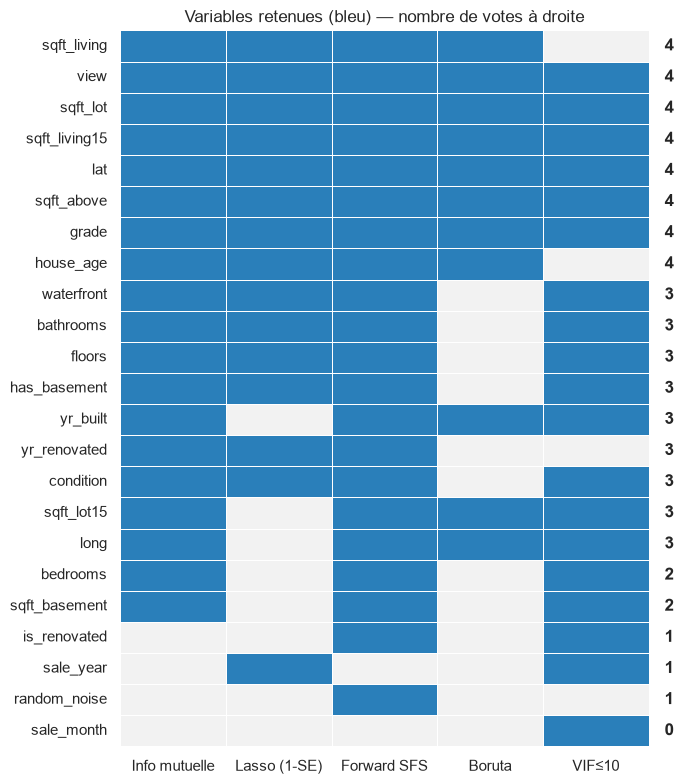

Consensus (>= 2/4 votes) : 19 variables
['sqft_living', 'view', 'sqft_lot', 'sqft_living15', 'lat', 'sqft_above', 'grade', 'house_age', 'waterfront', 'bathrooms', 'floors', 'has_basement', 'yr_built', 'yr_renovated', 'condition', 'sqft_lot15', 'long', 'bedrooms', 'sqft_basement']
Votes de la variable témoin random_noise : 1


In [21]:
rel_cols = ["Info mutuelle", "Lasso (1-SE)", "Forward SFS", "Boruta"]
votes["Nb votes"] = votes[rel_cols].sum(axis=1)
V = votes.sort_values("Nb votes", ascending=False)

fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(V[rel_cols + ["VIF≤10"]].astype(int), cmap=ListedColormap(["#f2f2f2", "#2a7fba"]),
            cbar=False, linewidths=.5, linecolor="white", ax=ax)
for i, n in enumerate(V["Nb votes"]): ax.text(len(rel_cols) + 1.15, i + .5, int(n), va="center", fontweight="bold")
ax.set_title("Variables retenues (bleu) — nombre de votes à droite"); plt.tight_layout(); plt.show()

THRESH = 2
consensus = list(V.index[V["Nb votes"] >= THRESH])
print(f"Consensus (>= {THRESH}/{len(rel_cols)} votes) : {len(consensus)} variables")
print(consensus)
print("Votes de la variable témoin random_noise :", int(V.loc["random_noise", "Nb votes"]))

### Retrait des redondances dans le consensus
Tant qu'une variable du consensus a un VIF > 10, on retire celle qui a le moins de votes.

In [22]:
final_feats = list(consensus)
while True:
    v = vif_table(final_feats)
    bad = v[v > 10]
    if bad.empty: break
    cand = pd.DataFrame({"votes": V.loc[bad.index, "Nb votes"], "mi": mi[bad.index]}).sort_values(["votes", "mi"])
    final_feats.remove(cand.index[0])

print("Retirées pour redondance :", [c for c in consensus if c not in final_feats])
print(f"\nSélection finale ({len(final_feats)} variables) :"); print(final_feats)

Retirées pour redondance : ['sqft_above', 'yr_built', 'sqft_basement']

Sélection finale (16 variables) :
['sqft_living', 'view', 'sqft_lot', 'sqft_living15', 'lat', 'grade', 'house_age', 'waterfront', 'bathrooms', 'floors', 'has_basement', 'yr_renovated', 'condition', 'sqft_lot15', 'long', 'bedrooms']


## 9. Export

In [23]:
V.to_csv("votes_selection_variables.csv")
pd.Series(final_feats, name="variables_finales").to_csv("variables_finales.csv", index=False)
print("Fichiers exportés : votes_selection_variables.csv, variables_finales.csv")

Fichiers exportés : votes_selection_variables.csv, variables_finales.csv
